# Case file 4 · The First Witness: a tiny transformer that draws silhouettes

<a href="https://colab.research.google.com/github/umanets/pixelsprite/blob/main/learn/04_tiny_transformer.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

We build a small transformer **from scratch**, about 70 lines of PyTorch, and teach it to draw 16×16
silhouettes one pixel at a time from a caption. This is the same idea as the final model, minus the colours.

**Time:** about 8 minutes on a laptop CPU (6 of them training), about 2 on a Colab GPU.
**You will learn:** tokens, embeddings, attention, next-token prediction, the training loop, loss in bits,
text conditioning and classifier-free guidance.

In [1]:
try:
    import pixelsprite
except ImportError:
    %pip -q install "pixelsprite[learn] @ git+https://github.com/umanets/pixelsprite"
import os, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
warnings.filterwarnings("ignore")
from huggingface_hub.utils import logging as hf_logging
hf_logging.set_verbosity_error()

In [2]:
import math, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from pixelsprite import sheet, mask_rgba
from pixelsprite.data import load_shard
from pixelsprite.text import TextEncoder

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
TRAIN_SECONDS = 360 if device == "cpu" else 120       # change me: more time = better drawings
print("device:", device)

device: cpu


## 1. Evidence → numbers
Each silhouette becomes a sequence of 256 **tokens**: 1 = solid, 0 = empty, read row by row.
Each caption becomes a list of 384 numbers from a ready-made sentence encoder (an **embedding**): captions with
similar meanings get similar lists. The encoder understands English, Russian and Ukrainian.

In [3]:
data = load_shard(n=24000, seed=0)
tokens = torch.as_tensor(data.mask.reshape(len(data), 256), dtype=torch.long)       # (N, 256) of 0/1
encoder = TextEncoder()
uniq = sorted(set(data.subject))
vec = dict(zip(uniq, encoder(uniq)))                                                 # one vector per subject
text = torch.stack([vec[s] for s in data.subject])                                   # (N, 384)
n_val = 1000
print("tokens", tuple(tokens.shape), "text vectors", tuple(text.shape), "| first row:", tokens[0, :16].tolist())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4284.36it/s]

tokens (24000, 256) text vectors (24000, 384) | first row: [0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0]


## 2. The model
* **Embeddings** turn each token (0, 1 or "start") and each position (0…255) into a vector of `d` numbers.
* **Attention**: every position asks "which earlier positions matter for me?" It computes a score for each
  earlier position (query · key), turns the scores into weights with softmax, and takes a weighted average of
  their values. The *causal mask* hides the future, so the model cannot peek at the pixel it must predict.
* An **MLP** (two linear layers) then thinks about what was gathered. Attention plus MLP is one **block**;
  we stack 4.
* The first token is the caption vector (projected to `d` numbers). The output at each position is 2 scores:
  "next pixel empty" vs "next pixel solid".

In [4]:
class Attention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.h, self.qkv, self.out = heads, nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.last = None                                   # attention weights of the last call (for pictures)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)   # each (B, h, T, D/h)
        score = q @ k.transpose(-2, -1) / math.sqrt(D // self.h)                           # (B, h, T, T)
        future = torch.ones(T, T, dtype=torch.bool, device=x.device).triu(1)
        weight = score.masked_fill(future, float("-inf")).softmax(-1)                      # rows sum to 1
        self.last = weight.detach()
        y = (weight @ v).transpose(1, 2).reshape(B, T, D)
        return self.out(y)

class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.att, self.ln2 = nn.LayerNorm(d), Attention(d, heads), nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x):
        x = x + self.att(self.ln1(x))                      # "+": the block adds to what was there (residual)
        return x + self.mlp(self.ln2(x))

class TinyMaskGPT(nn.Module):
    START = 2
    def __init__(self, d=96, layers=4, heads=4, text_dim=384):
        super().__init__()
        self.tok, self.pos = nn.Embedding(3, d), nn.Embedding(256, d)
        self.text, self.null = nn.Linear(text_dim, d), nn.Parameter(torch.zeros(d))
        self.blocks = nn.ModuleList(Block(d, heads) for _ in range(layers))
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, 2)

    def forward(self, text, prev):
        """text (B,384) or None; prev (B,T) tokens shifted right (START first) -> scores (B,T,2)."""
        B, T = prev.shape
        c = self.null.expand(B, -1) if text is None else self.text(text)
        x = torch.cat([c[:, None], self.tok(prev) + self.pos(torch.arange(T, device=prev.device))], 1)
        for b in self.blocks:
            x = b(x)
        return self.head(self.ln(x[:, 1:]))

model = TinyMaskGPT().to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

509,666 parameters


## 3. Training: guess the next pixel, measure the surprise, nudge the weights
For every position the model outputs probabilities for "empty" and "solid". The **loss** is the surprise at the
right answer, −log p, averaged over pixels. We report it in **bits per silhouette** (×256 / ln 2), the same
unit as in case file 3. In 10% of the examples we hide the caption (replace it with a learned "null"),
which will let us use guidance later.

485 steps in 361s; validation: 58.1 bits per silhouette (256 without learning)


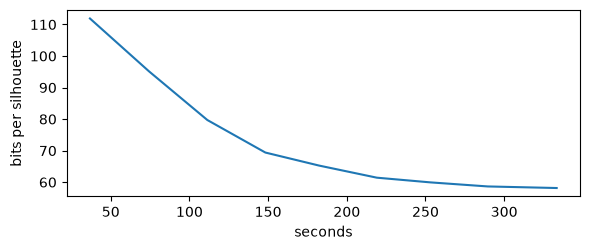

In [5]:
def batch_loss(idx, drop_text=0.1):
    x = tokens[idx].to(device)
    prev = torch.cat([torch.full((len(idx), 1), TinyMaskGPT.START, device=device), x[:, :-1]], 1)
    t = text[idx].to(device)
    if drop_text:
        keep = (torch.rand(len(idx), 1, device=device) > drop_text).float()
        t_proj = model.text(t) * keep + model.null * (1 - keep)
        logits = forward_with_cond(t_proj, prev)
    else:
        logits = model(t, prev)
    return F.cross_entropy(logits.reshape(-1, 2), x.reshape(-1))

def forward_with_cond(c, prev):
    B, T = prev.shape
    x = torch.cat([c[:, None], model.tok(prev) + model.pos(torch.arange(T, device=prev.device))], 1)
    for b in model.blocks:
        x = b(x)
    return model.head(model.ln(x[:, 1:]))

opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=0.01)
train_idx = np.arange(n_val, len(tokens))
val_idx = torch.arange(n_val)
history, t0, step = [], time.time(), 0
model.train()
while time.time() - t0 < TRAIN_SECONDS:
    idx = torch.as_tensor(np.random.choice(train_idx, 64))
    loss = batch_loss(idx)
    opt.zero_grad(); loss.backward(); opt.step(); step += 1
    if step % 50 == 0:
        model.eval()
        with torch.no_grad():
            val = batch_loss(val_idx, drop_text=0).item()
        model.train()
        history.append((time.time() - t0, val * 256 / math.log(2)))
print(f"{step} steps in {time.time() - t0:.0f}s; validation: {history[-1][1]:.1f} bits per silhouette (256 without learning)")
plt.figure(figsize=(6, 2.6)); plt.plot(*zip(*history)); plt.xlabel("seconds"); plt.ylabel("bits per silhouette"); plt.tight_layout(); plt.show()

## 4. Drawing: one pixel at a time
To draw, we feed what we have so far, read the probability of "solid" for the next pixel, flip a weighted coin,
append the result, repeat 256 times.

**Classifier-free guidance** asks the model twice, with the caption and without it, and pushes the answer away
from the caption-free one: score = score_without + g · (score_with − score_without). g = 1 is the plain model;
g > 1 follows the caption harder.

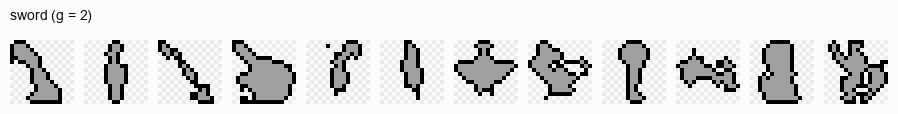

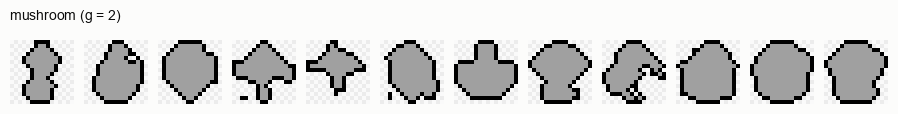

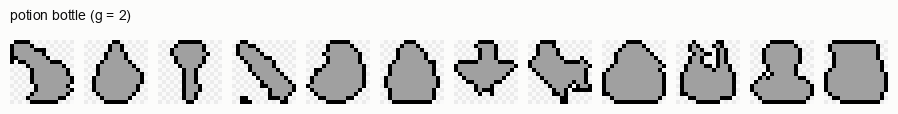

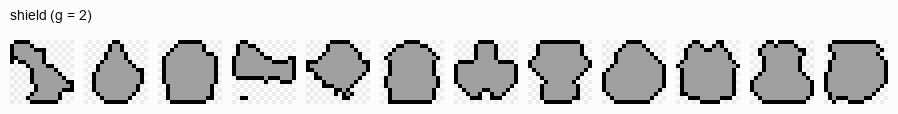

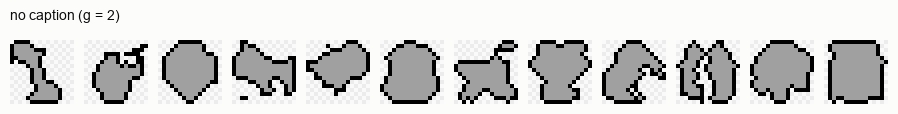

In [6]:
@torch.no_grad()
def draw(caption, n=12, g=1.0, seed=0):
    model.eval()
    gen = torch.Generator(device=device).manual_seed(seed)
    t = (encoder([caption]) if caption else None)
    out = torch.full((n, 1), TinyMaskGPT.START, device=device)
    for i in range(256):
        lc = model(None if t is None else t.to(device).expand(n, -1), out)[:, -1]
        if t is not None and g != 1.0:
            lu = model(None, out)[:, -1]
            lc = lu + g * (lc - lu)
        p_solid = lc.softmax(-1)[:, 1]
        nxt = (torch.rand(n, generator=gen, device=device) < p_solid).long()
        out = torch.cat([out, nxt[:, None]], 1)
    return out[:, 1:].view(n, 16, 16).bool().cpu().numpy()

# The same seed for every caption: the coin flips are identical, so any difference comes from the caption.
for cap in ["sword", "mushroom", "potion bottle", "shield", None]:
    display(sheet([mask_rgba(m) for m in draw(cap, g=2.0)], f"{cap or 'no caption'} (g = 2)", scale=4, cols=12))

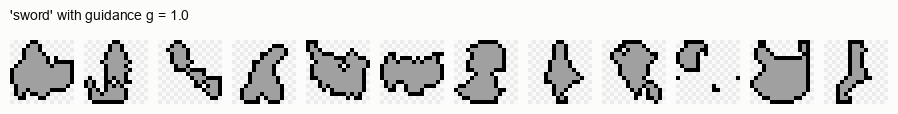

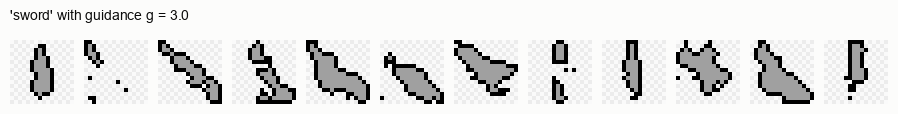

In [7]:
for g in (1.0, 3.0):
    display(sheet([mask_rgba(m) for m in draw("sword", g=g, seed=1)], f"'sword' with guidance g = {g}", scale=4, cols=12))

## 5. Where does the model look?
The attention weights of the last block for one pixel in the middle of the picture (averaged over heads).
Bright squares are the earlier pixels it relies on most.

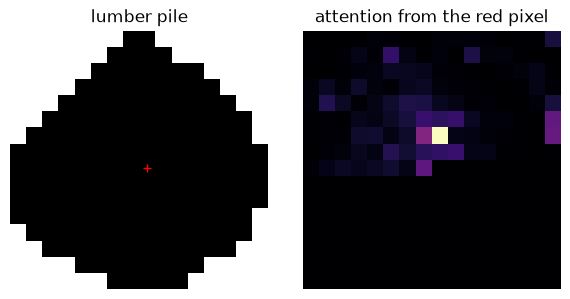

In [8]:
with torch.no_grad():
    i = 0
    x = tokens[i:i + 1].to(device)
    prev = torch.cat([torch.full((1, 1), TinyMaskGPT.START, device=device), x[:, :-1]], 1)
    model(text[i:i + 1].to(device), prev)
    pos = 8 * 16 + 8                                        # predict the pixel at row 8, column 8
    # sequence = [caption, START, pixel 0, pixel 1, ...]: the output at position pos + 1 predicts pixel `pos`,
    # and pixel j sits at position j + 2, i.e. at w[j + 1] below
    w = model.blocks[-1].att.last[0].mean(0)[pos + 1, 1:]
    img = np.zeros(256); img[:pos] = w[1:pos + 1].cpu().numpy()
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(data.mask[i], cmap="gray_r"); ax[0].set_title(data.subject[i][:24]); ax[0].plot(8, 8, "r+")
ax[1].imshow(img.reshape(16, 16), cmap="magma"); ax[1].set_title("attention from the red pixel")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Your turn
1. Double `TRAIN_SECONDS`. How many bits do you save? Do the swords get sharper?
2. Try captions in Russian or Ukrainian (`"меч"`, `"гриб"`). Why can this tiny model understand them at all?
3. Make the model bigger (`d=128, layers=6`) and train for the same time. Bigger is not always better when time is short. Why?